# Phase 3 — Propose and audit speaker-disjoint splits

**Goal:** Use the Phase 2 Narration labels to propose training, validation and test sets for a first IPA-Whisper baseline. The split is based on connected speaker groups, recording sessions and exact decoded waveforms. **Do not train against a proposed split until its audit and category plots have been reviewed and the final freeze cell is explicitly enabled.**

Current first-baseline policy: set aside the 42 clips in the Phase 2.5 symbol queue; keep every remaining `train_only` clip in training; keep all proposed links together. This is a conservative policy, not an adjudication of speaker identity or punctuation.

The notebook reads local data, performs a full exact-waveform hash pass, and writes only derived local outputs when you run it. It does not overwrite raw audio, transcripts, or previous phase outputs.

In [1]:
from pathlib import Path
from datetime import datetime
from io import BytesIO
import hashlib
import json
import random

import pandas as pd
import pyarrow.parquet as pq
import soundfile as sf
from IPython.display import display

current = Path.cwd().resolve()
project = next(
    (folder for folder in (current, *current.parents)
     if (folder / "manifests/master_A_v1_1.parquet").is_file()),
    None,
)
if project is None:
    raise FileNotFoundError("Open this notebook inside the BTP project.")

phase2_path = project / "outputs/phase2_20261031_205009/phase2_candidates.parquet"
queue_path = project / "outputs/phase2_5_20261031_215057/symbol_review_queue.csv"
master_path = project / "manifests/master_A_v1_1.parquet"
for path in (phase2_path, queue_path, master_path):
    if not path.is_file():
        raise FileNotFoundError(path)

def sha256_file(path):
    digest = hashlib.sha256()
    with path.open("rb") as handle:
        for block in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()

input_hashes = {str(path.relative_to(project)): sha256_file(path)
                for path in (phase2_path, queue_path, master_path)}
print("Input files and SHA-256 hashes:")
for name, digest in input_hashes.items():
    print(name, digest)

Input files and SHA-256 hashes:
outputs/phase2_20261031_205009/phase2_candidates.parquet cdffb2605f5e0de2168fbc093dc4c7937b808437aa20b0fb5705b596bd7b1681
outputs/phase2_5_20261031_215057/symbol_review_queue.csv 67e6e0bcc8e247a36a88e239a9d3bcfcf5c9e3a78cdbb9d06e3a21e77d36e22b
manifests/master_A_v1_1.parquet 2cbaba574f25c43710c41706d7011d71c0f9af691b5b29c71cc2618f9bf57dab


## 1. Apply the declared first-baseline exclusions

The Phase 2.5 queue identifies 42 clips with punctuation or accent questions. Set them aside from the first supervised experiment, while preserving them in their existing source manifests. Metadata for thesis plots comes from the master through a one-to-one ID join. Original Hugging Face split labels are retained only as historical metadata.

In [2]:
candidate = pd.read_parquet(phase2_path)
queue = pd.read_csv(queue_path, encoding="utf-8-sig")
category_columns = ["sample_id", "gender", "age_group", "domain",
                    "recording_month", "education_level"]
categories = pd.read_parquet(master_path, columns=category_columns)
if candidate["sample_id"].duplicated().any() or categories["sample_id"].duplicated().any():
    raise ValueError("Sample IDs must be unique in both input tables.")
if queue["sample_id"].duplicated().any():
    raise ValueError("Symbol queue contains duplicate sample IDs.")
if not set(queue["sample_id"]).issubset(set(candidate["sample_id"])):
    raise ValueError("Symbol queue contains IDs outside Phase 2 candidates.")

work = candidate.loc[~candidate["sample_id"].isin(queue["sample_id"])].copy()
work = work.merge(categories, on="sample_id", how="left",
                  validate="one_to_one", indicator=True)
if not work["_merge"].eq("both").all():
    raise ValueError("Some candidates lack master metadata.")
work.drop(columns="_merge", inplace=True)
work.reset_index(drop=True, inplace=True)
if work["transcript_phase2"].isna().any():
    raise ValueError("A retained row lacks its Phase 2 target.")

for field in category_columns[1:]:
    work[field] = work[field].fillna("Unknown").astype(str)

print("Phase 2 candidates:", len(candidate))
print("Set aside for targeted symbol review:", len(queue))
print("Initial split pool:", len(work))
print("Decoded hours:", round(work["duration_decoded"].sum() / 3600, 3))
print("Train-only rows in split pool:", int(work["train_only"].sum()))

Phase 2 candidates: 5086
Set aside for targeted symbol review: 42
Initial split pool: 5044
Decoded hours: 14.625
Train-only rows in split pool: 965


## 2. Hash decoded audio to find exact waveform duplicates

This reads only the embedded audio column of each relevant Narration Parquet shard, decodes each selected WAV, and hashes the 16-bit sample sequence together with its sample rate. It may take several minutes and uses more memory than the metadata cells. Different byte headers around identical PCM samples will still match. This detects **exact** decoded duplicates; it does not establish that similar recordings are distinct.

In [3]:
raw_root = (project / "raw/A_narration").resolve()
locator = work["audio_path"].astype(str).str.rsplit("#row=", n=1, expand=True)
if locator.shape[1] != 2 or locator[1].isna().any():
    raise ValueError("Unexpected audio_path locator format.")
work["_parquet_rel"] = locator[0]
work["_parquet_row"] = pd.to_numeric(locator[1], errors="raise").astype(int)

wave_hash = pd.Series(index=work.index, dtype="string")
for rel_path, indices in work.groupby("_parquet_rel", sort=True).groups.items():
    parquet_path = (project / rel_path).resolve()
    if not parquet_path.is_relative_to(raw_root):
        raise ValueError(f"Audio path outside Narration raw data: {rel_path}")
    audio_column = pq.read_table(parquet_path, columns=["audio"]).column("audio")
    for index in indices:
        row_number = int(work.at[index, "_parquet_row"])
        if row_number < 0 or row_number >= len(audio_column):
            raise IndexError(f"Invalid Parquet row {row_number} in {rel_path}")
        embedded = audio_column[row_number].as_py()
        if not embedded or not embedded.get("bytes"):
            raise ValueError(f"Missing embedded audio for {work.at[index, 'sample_id']}")
        samples, sample_rate = sf.read(
            BytesIO(embedded["bytes"]), dtype="int16", always_2d=True
        )
        if len(samples) == 0:
            raise ValueError(f"Empty decoded audio for {work.at[index, 'sample_id']}")
        digest = hashlib.sha256()
        digest.update(int(sample_rate).to_bytes(4, "little"))
        digest.update(samples.tobytes(order="C"))
        wave_hash.at[index] = digest.hexdigest()

work["exact_waveform_sha256"] = wave_hash
if work["exact_waveform_sha256"].isna().any():
    raise RuntimeError("Some candidate audio was not hashed.")
duplicate_groups = work.groupby("exact_waveform_sha256").size()
print("Waveforms hashed:", len(work))
print("Exact duplicate waveform groups:", int(duplicate_groups.gt(1).sum()))
print("Rows in exact duplicate groups:",
      int(duplicate_groups[duplicate_groups.gt(1)].sum()))

Waveforms hashed: 5044
Exact duplicate waveform groups: 0
Rows in exact duplicate groups: 0


## 3. Connect all rows that must stay in one partition

Two rows are connected if they share a proposed speaker group, recording session or exact waveform hash. Connections propagate: if A shares a speaker with B and B shares a session with C, all three stay together. Any component containing a train-only row becomes train-only. This rule protects evaluation independence while speaker proposals are unresolved.

In [4]:
parent = list(range(len(work)))
size = [1] * len(work)

def find(index):
    while parent[index] != index:
        parent[index] = parent[parent[index]]
        index = parent[index]
    return index

def union(left, right):
    left, right = find(left), find(right)
    if left == right:
        return
    if size[left] < size[right]:
        left, right = right, left
    parent[right] = left
    size[left] += size[right]

for key in ("speaker_group_id", "speaker_id", "speaker_id_raw",
            "recording_session_id", "exact_waveform_sha256"):
    for indices in work.groupby(key, dropna=False).indices.values():
        indices = list(indices)
        for index in indices[1:]:
            union(indices[0], index)

work["split_component"] = [find(index) for index in range(len(work))]
work["component_id"] = work.groupby("split_component")["sample_id"].transform("min")
work["train_only_effective"] = work.groupby("split_component")[
    "train_only"
].transform("any").astype(bool)
components = (
    work.groupby("component_id")
    .agg(
        clips=("sample_id", "size"),
        seconds=("duration_decoded", "sum"),
        train_only=("train_only_effective", "any"),
        speaker_groups=("speaker_group_id", "nunique"),
        sessions=("recording_session_id", "nunique"),
    )
    .reset_index()
)
components["hours"] = components["seconds"] / 3600
print("Connected components:", len(components))
print("Train-only components:", int(components["train_only"].sum()))
print("Train-only rows after connection:", int(work["train_only_effective"].sum()))
display(components.sort_values("hours", ascending=False).head(10))

Connected components: 44
Train-only components: 8
Train-only rows after connection: 965


,component_id,clips,seconds,train_only,speaker_groups,sessions,hours
3,A_000008,810,13159.969,False,1,427,3.655547
5,A_000036,657,8583.317,False,1,321,2.384255
4,A_000022,444,7174.473,False,1,313,1.992909
0,A_000001,377,3363.712,True,1,242,0.934364
2,A_000006,222,2655.212,True,1,168,0.737559
1,A_000005,226,2291.688,False,1,167,0.636580
10,A_000067,218,1635.040,False,1,37,0.454178
29,A_000296,135,1271.780,False,1,1,0.353272
21,A_000163,100,937.240,True,1,2,0.260344
18,A_000133,86,935.940,False,1,1,0.259983


## 4. Propose train, validation and test component assignments

The target is about 70%/15%/15% of **audio hours**. With uneven speaker groups, exact percentages may be impossible. This deterministic greedy proposal caps any single selected held-out component at 75% of one held-out target, then fills each held-out side with smaller whole components. Inspect the actual hours, speakers and category balance before accepting it. No test data is used to tune a model here.

In [5]:
SEED = 20261031
TARGET_VAL = 0.15
TARGET_TEST = 0.15
total_hours = float(components["hours"].sum())
targets = {"validation": total_hours * TARGET_VAL,
           "test": total_hours * TARGET_TEST}
rng = random.Random(SEED)
eligible = components.loc[~components["train_only"]].to_dict("records")
rng.shuffle(eligible)
assignments = {row["component_id"]: "train"
               for row in components.to_dict("records")}

for split_name in ("validation", "test"):
    target = targets[split_name]
    current_hours = 0.0
    while True:
        options = [
            row for row in eligible
            if assignments[row["component_id"]] == "train"
            and row["hours"] <= 0.75 * target
            and abs(target - (current_hours + row["hours"]))
                < abs(target - current_hours)
        ]
        if not options:
            break
        choice = min(
            options,
            key=lambda row: (
                abs(target - (current_hours + row["hours"])),
                row["component_id"],
            ),
        )
        assignments[choice["component_id"]] = split_name
        current_hours += choice["hours"]
    print(split_name, "target hours", round(target, 3),
          "proposed hours", round(current_hours, 3))

work["proposed_split"] = work["component_id"].map(assignments)
if work["proposed_split"].isna().any():
    raise RuntimeError("Some rows have no split assignment.")
summary = (
    work.groupby("proposed_split")
    .agg(
        clips=("sample_id", "size"),
        hours=("duration_decoded", lambda values: values.sum() / 3600),
        components=("component_id", "nunique"),
        public_speakers=("speaker_id", "nunique"),
        proposed_speaker_groups=("speaker_group_id", "nunique"),
    )
    .reindex(["train", "validation", "test"], fill_value=0)
)
summary["hour_share"] = summary["hours"] / summary["hours"].sum()
display(summary)
if (summary.loc[["validation", "test"], "components"] < 2).any():
    print("REVIEW: A held-out split has fewer than two independent components.")

validation target hours 2.194 proposed hours 2.194
test target hours 2.194 proposed hours 1.93


,clips,hours,components,public_speakers,proposed_speaker_groups,hour_share
proposed_split,,,,,,
train,2876,10.500004,11,14,12,0.717973
validation,1428,2.194461,7,9,7,0.150054
test,740,1.930039,26,26,26,0.131973


## 5. Audit leakage and repeated prompts

The component construction should make known speaker-group, session and exact-waveform overlap zero across splits. Repeated transcript text is measured separately: repeated prompts may be legitimate elicitation and should not be called duplicate audio. Report their overlap transparently.

In [6]:
def cross_split_keys(column):
    counts = work.groupby(column, dropna=False)["proposed_split"].nunique()
    return int(counts.gt(1).sum())

overlap = {
    "component": cross_split_keys("component_id"),
    "speaker_group": cross_split_keys("speaker_group_id"),
    "speaker_id": cross_split_keys("speaker_id"),
    "raw_speaker_id": cross_split_keys("speaker_id_raw"),
    "recording_session": cross_split_keys("recording_session_id"),
    "exact_waveform": cross_split_keys("exact_waveform_sha256"),
    "transcript_text": cross_split_keys("transcript_phase2"),
}
train_only_in_heldout = int(work.loc[
    work["train_only_effective"], "proposed_split"
].ne("train").sum())
print("Cross-split overlap counts:", overlap)
print("Train-only rows outside training:", train_only_in_heldout)
if any(overlap[key] for key in
       ("component", "speaker_group", "speaker_id", "raw_speaker_id",
        "recording_session", "exact_waveform")):
    raise RuntimeError("Known leakage detected. Do not freeze this proposal.")
if train_only_in_heldout:
    raise RuntimeError("Train-only rows entered a held-out split.")
print("Known structural leakage checks passed; prompt overlap is diagnostic.")

Cross-split overlap counts: {'component': 0, 'speaker_group': 0, 'speaker_id': 0, 'raw_speaker_id': 0, 'recording_session': 0, 'exact_waveform': 0, 'transcript_text': 1}
Train-only rows outside training: 0
Known structural leakage checks passed; prompt overlap is diagnostic.


## 6. Visual review for your thesis

The first chart shows clips, hours and number of proposed speaker groups in each split. The category charts show **hours** by gender, age, domain, recording month, education level and speaker status. Missing category values appear as `Unknown`. These are descriptive metadata views; a balanced category chart does not prove speaker identities are correct.

Use the plots to judge whether this split is reasonable before freezing it. A holdout may differ from the overall population because whole speaker groups cannot be divided.

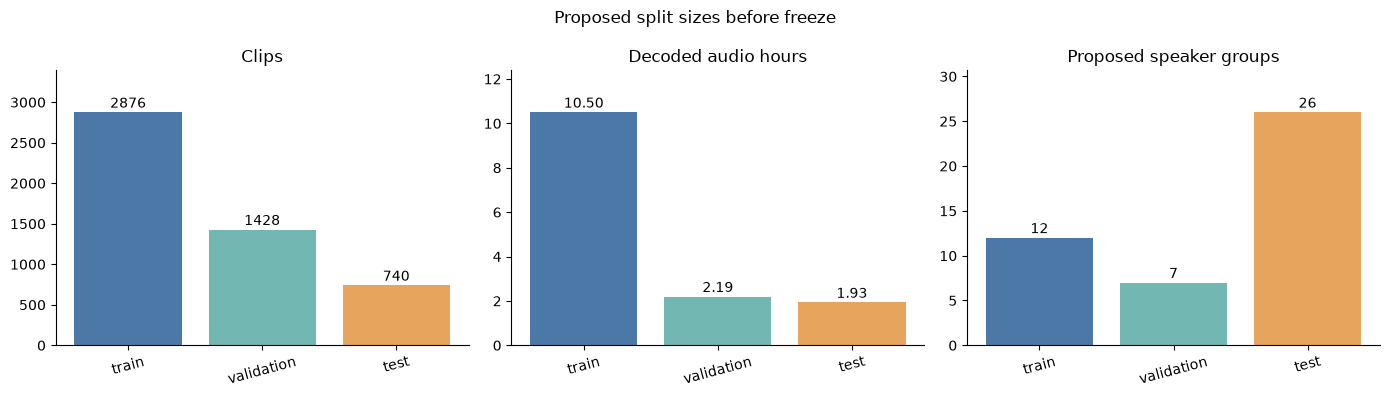

In [7]:
try:
    import matplotlib.pyplot as plt
except ImportError:
    print("Matplotlib is unavailable. In a separate cell run %pip install matplotlib.")
else:
    fig, axes = plt.subplots(1, 3, figsize=(14, 4))
    for ax, field, title in zip(
        axes, ("clips", "hours", "proposed_speaker_groups"),
        ("Clips", "Decoded audio hours", "Proposed speaker groups")
    ):
        values = summary[field]
        ax.bar(values.index, values.values,
               color=["#4c78a8", "#72b7b2", "#e6a45c"])
        ax.set_title(title)
        ax.tick_params(axis="x", rotation=15)
        for i, value in enumerate(values):
            ax.text(i, value + max(values.max() * 0.02, 0.02),
                    f"{value:.2f}" if field == "hours" else f"{int(value)}",
                    ha="center")
        ax.set_ylim(0, max(values.max() * 1.18, 1))
        ax.spines[["top", "right"]].set_visible(False)
    fig.suptitle("Proposed split sizes before freeze")
    fig.tight_layout()
    plt.show()

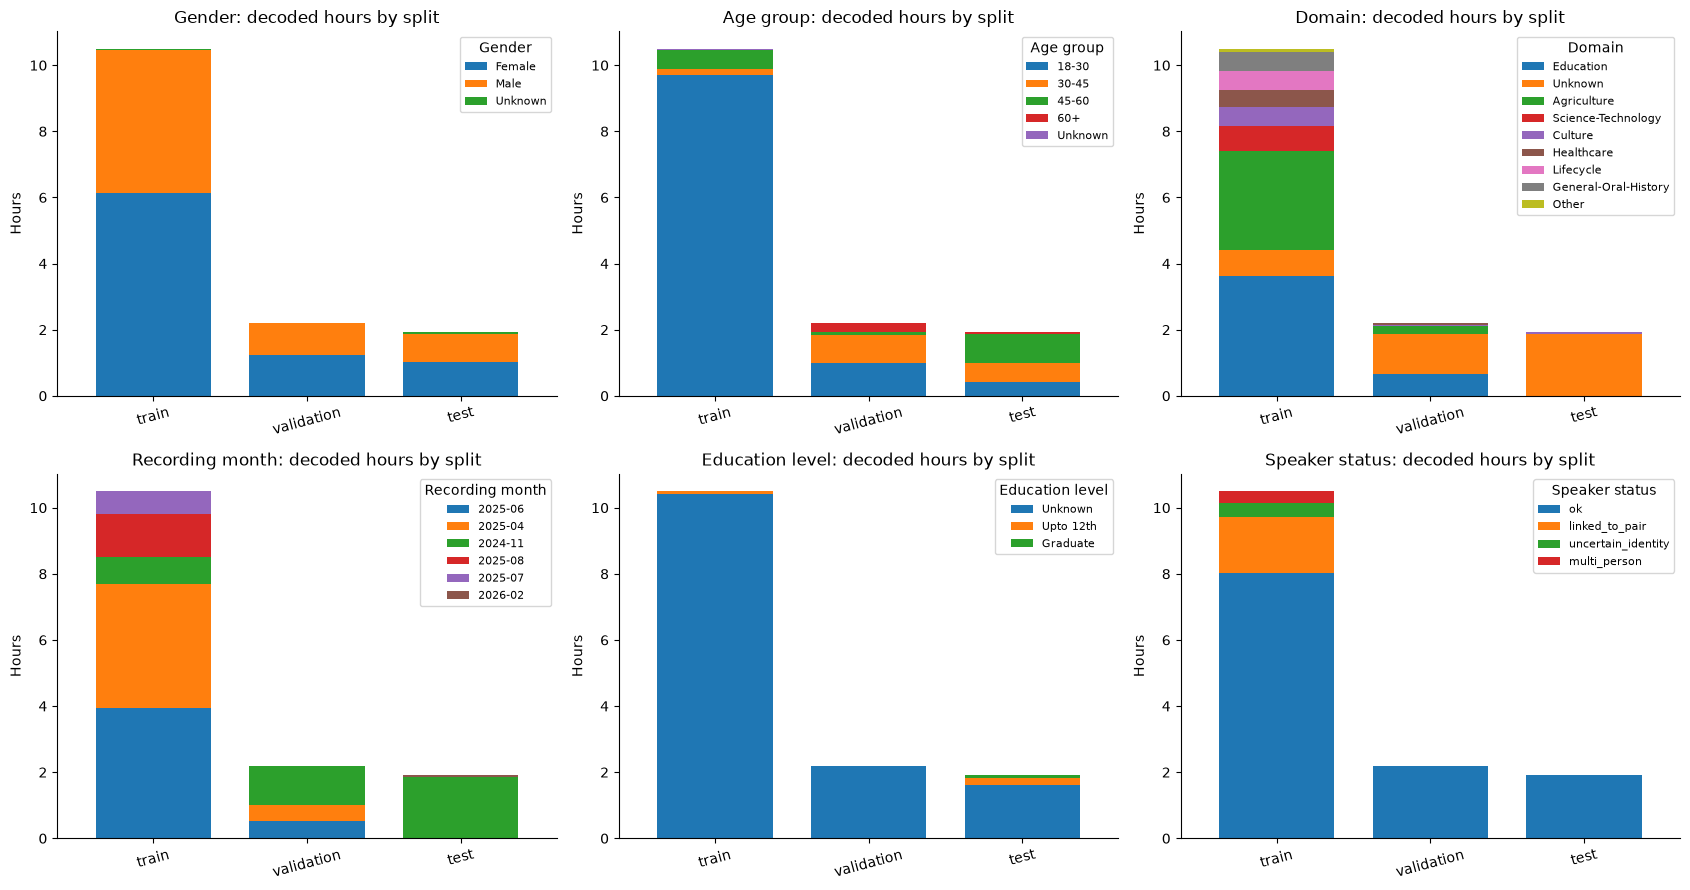

In [8]:
def category_hours(field, top_n=8):
    table = work.assign(hours=work["duration_decoded"] / 3600).pivot_table(
        index="proposed_split", columns=field, values="hours",
        aggfunc="sum", fill_value=0
    ).reindex(["train", "validation", "test"], fill_value=0)
    major = table.sum().nlargest(top_n).index
    other = table.drop(columns=major).sum(axis=1)
    table = table.loc[:, major].copy()
    if other.gt(0).any():
        table["Other"] = other
    return table

try:
    import matplotlib.pyplot as plt
except ImportError:
    print("Matplotlib is unavailable; category plots skipped.")
else:
    fig, axes = plt.subplots(2, 3, figsize=(17, 9))
    for ax, field, title in zip(
        axes.flat,
        ("gender", "age_group", "domain", "recording_month",
         "education_level", "speaker_status"),
        ("Gender", "Age group", "Domain", "Recording month",
         "Education level", "Speaker status"),
    ):
        table = category_hours(field)
        table.plot(kind="bar", stacked=True, ax=ax, legend=False, width=0.75)
        ax.set_title(f"{title}: decoded hours by split")
        ax.set_xlabel("")
        ax.set_ylabel("Hours")
        ax.tick_params(axis="x", rotation=15)
        ax.spines[["top", "right"]].set_visible(False)
        ax.legend(title=title, fontsize=8, loc="upper right")
    fig.tight_layout()
    plt.show()

## 7. Save the *proposal* and its audit

This saves a versioned local proposal, category counts, overlap audit, and input hashes. It does not mark the split frozen. Keep all source data and prior phase files intact. Do not push row-level manifests or speaker metadata to the source-only GitHub repository.

In [9]:
run_id = datetime.now().astimezone().strftime("%Y%m%d_%H%M%S")
output_dir = project / "outputs" / f"phase3_{run_id}"
output_dir.mkdir(parents=True, exist_ok=False)
proposal_path = output_dir / "split_proposal.parquet"
summary_path = output_dir / "split_summary.csv"
audit_path = output_dir / "audit.json"

work.drop(columns=["_parquet_rel", "_parquet_row"]).to_parquet(
    proposal_path, index=False
)
summary.to_csv(summary_path)

audit_record = {
    "phase": 3,
    "status": "proposed_not_frozen",
    "created_at": datetime.now().astimezone().isoformat(timespec="seconds"),
    "seed": SEED,
    "input_sha256": input_hashes,
    "excluded_symbol_ids": sorted(queue["sample_id"].tolist()),
    "initial_candidate_rows": int(len(candidate)),
    "proposed_pool_rows": int(len(work)),
    "proposed_pool_hours": float(total_hours),
    "cross_split_overlap": overlap,
    "train_only_in_heldout": train_only_in_heldout,
    "prompt_overlap_is_diagnostic": True,
    "final_split_approved": False,
}
audit_path.write_text(json.dumps(audit_record, indent=2) + "\n",
                      encoding="utf-8")
for path in (phase2_path, queue_path, master_path):
    if sha256_file(path) != input_hashes[str(path.relative_to(project))]:
        raise RuntimeError(f"Input changed during Phase 3: {path}")
print("Proposal saved:", output_dir)
print("Proposal SHA-256:", sha256_file(proposal_path))
print("Inputs unchanged; split remains proposed, not frozen.")

Proposal saved: /Users/kanchanpotdar/Downloads/BTP/outputs/phase3_20261031_223422
Proposal SHA-256: 6fc903dd53927da5eb623e67f062df091e5c9cc91ad29958945a9206ae8c4e92
Inputs unchanged; split remains proposed, not frozen.


## 8. Freeze only after reviewing the proposal

Review the charts and audit. Confirm that held-out groups are suitable for a primary unseen-speaker result and that the conservative treatment of 42 symbol cases and train-only groups is recorded. Then change `APPROVE_FREEZE` to `True` in the final cell. It copies the approved proposal to a frozen manifest and records hashes. Until then, the split is only a proposal.

In [10]:
APPROVE_FREEZE = False  # Change to True only after manual review above.

if not APPROVE_FREEZE:
    print("Split not frozen. Review the proposal and category balance first.")
else:
    if any(overlap[key] for key in
           ("component", "speaker_group", "speaker_id", "raw_speaker_id",
            "recording_session", "exact_waveform")):
        raise RuntimeError("Cannot freeze a proposal with known leakage.")
    if train_only_in_heldout:
        raise RuntimeError("Cannot freeze train-only rows in validation/test.")
    if (summary.loc[["validation", "test"], "clips"] == 0).any():
        raise RuntimeError("Cannot freeze an empty held-out split.")
    frozen_path = output_dir / "frozen_split.parquet"
    if frozen_path.exists():
        raise FileExistsError(frozen_path)
    frozen = work.drop(columns=["_parquet_rel", "_parquet_row"]).copy()
    frozen = frozen.rename(columns={"proposed_split": "final_split"})
    frozen.to_parquet(frozen_path, index=False)
    audit_record["status"] = "frozen"
    audit_record["final_split_approved"] = True
    audit_record["frozen_manifest_sha256"] = sha256_file(frozen_path)
    audit_path.write_text(json.dumps(audit_record, indent=2) + "\n",
                          encoding="utf-8")
    print("Frozen split:", frozen_path)
    print("SHA-256:", audit_record["frozen_manifest_sha256"])

Split not frozen. Review the proposal and category balance first.


## Phase 3 conclusion

**Status: Split proposed and structurally audited; not frozen.**

- The first-baseline pool contains 5,044 clips and approximately 14.625 decoded hours after setting aside the 42 Phase 2.5 symbol-review clips.
- All 5,044 included waveforms were decoded and hashed. No exact decoded-waveform duplicate groups were found.
- Speaker IDs, raw speaker IDs, proposed speaker groups, recording sessions, and exact waveforms were connected into 44 split components. Eight components are train-only.
- Proposed splits: train 2,876 clips / 10.500 hours / 11 components; validation 1,428 clips / 2.194 hours / 7 components; test 740 clips / 1.930 hours / 26 components.
- Known cross-split overlap is zero for components, speaker IDs, speaker groups, sessions, and exact waveforms. No train-only clips entered validation or test.
- One exact normalized transcript occurs across train, validation, and test in three separate clips. This is measured prompt overlap, not an exact-audio duplicate.
- The category plots show substantial imbalance. Test is 96.4% November 2024 audio, while train is 7.6%; domain metadata is Unknown for 96.4% of test hours. Train is 92.4% age 18–30 by hours, versus 22.0% in test. Median clip durations are 12.25 seconds (train), 2.01 (validation), and 7.20 (test). Gender proportions are more similar.
- **Decision:** Keep this manifest as a documented proposal. Revise the group assignment and inspect the revised category and duration distributions before setting `APPROVE_FREEZE = True`. Perfect category matching may be impossible with whole speaker groups; describe any remaining differences in the final report.
- No model has been evaluated and no frozen split has been produced.